In [1]:
from sklearn.metrics import roc_curve,roc_auc_score
import numpy as np

y_true = np.array([1, 1, 0, 0])
y_score = np.array([0.9, 0.7, 0.6, 0.2])

positive = y_score[y_true == 1]
negative = y_score[y_true == 0]

comparisons = [
    1 if p > n else 0.5 if p == n else 0
    for p in positive
    for n in negative
]

auc = np.mean(comparisons)
print("ROC-AUC:", auc)  # 0.75

ROC-AUC: 1.0


ROC-AUC: 0.9953703703703703


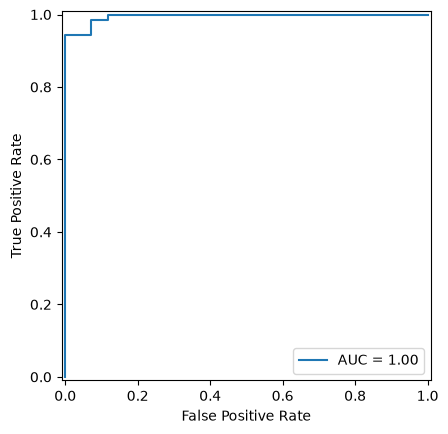

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    RocCurveDisplay
)
import matplotlib.pyplot as plt

X, y = load_breast_cancer(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)

# Scores for class 1
y_prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", auc)

RocCurveDisplay(
    fpr=fpr,
    tpr=tpr,
    roc_auc=auc
).plot()

plt.show()